In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
import os
import pickle

# Define sectors and their representative stocks
sectors = {
    'Technology': ['AAPL', 'MSFT', 'GOOGL', 'NVDA', 'AMD', 'INTC', 'CSCO', 'ORCL', 'QCOM', 'IBM'],
    'Financials': ['JPM', 'BAC', 'WFC', 'GS', 'MS', 'C', 'BLK', 'SCHW', 'AXP', 'USB'],
    'Healthcare': ['JNJ', 'PFE', 'MRK', 'GILD', 'BMY', 'ABBV', 'AMGN', 'LLY', 'CVS', 'UNH'],
    'Consumer_Discretionary': ['AMZN', 'TSLA', 'HD', 'NKE', 'MCD', 'SBUX', 'TGT', 'LOW', 'DIS', 'F'],
    'Energy': ['XOM', 'CVX', 'BP', 'SLB', 'KMI', 'COP', 'OXY', 'VLO', 'PSX', 'HAL'],
    'Industrials': ['CAT', 'GE', 'MMM', 'BA', 'HON', 'UNP', 'RTX', 'DE', 'LMT', 'UPS'],
    'Consumer_Staples': ['PG', 'KO', 'PEP', 'WMT', 'CL', 'COST', 'MO', 'KMB', 'GIS', 'KR'],
    'Utilities': ['DUK', 'SO', 'NEE', 'AEP', 'EXC', 'D', 'ED', 'PEG', 'XEL', 'SRE'],
    'Materials': ['PPG', 'DD', 'NEM', 'FCX', 'LYB', 'ECL', 'APD', 'SHW', 'VMC', 'MLM']
}

# Define economic cycle phases and associated sectors
economic_phases = {
    'Early_Recovery': ['Consumer_Discretionary', 'Financials', 'Industrials'],
    'Mid_Cycle_Expansion': ['Technology', 'Industrials'],
    'Late_Cycle_Peak': ['Energy', 'Materials', 'Utilities'],
    'Recession_Contraction': ['Healthcare', 'Consumer_Staples', 'Utilities']
}

# Define the time period for data and transaction fee
end_date = datetime.now()
start_date = end_date - timedelta(days=10000)
transaction_fee = 0.001  # 0.1% fee in log return terms
window = 50  # Rolling window for ranking (e.g., 252 trading days ~ 1 year)

# Fetch stock data from yfinance
def fetch_stock_data(tickers, start_date, end_date):
    data = yf.download(tickers, start=start_date, end=end_date, progress=False)['Close']
    return data
all_tickers = list(set(ticker for tickers in sectors.values() for ticker in tickers))
data = fetch_stock_data(all_tickers, start_date, end_date)


/tmp/ipython-input-190469308.py:38: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, start=start_date, end=end_date, progress=False)['Close']


In [ ]:
import scipy.cluster.hierarchy as hcluster
from scipy.spatial.distance import squareform

def get_sector_returns(log_returns):
    sector_returns = pd.DataFrame(index=log_returns.index)
    for sector, ticks in sectors.items():
        valid_ticks = [t for t in ticks if t in log_returns.columns]
        if valid_ticks:
            sector_returns[sector] = log_returns[valid_ticks].mean(axis=1)
    return sector_returns

def split_data(df, test_size=0.2):
    split_idx = int(len(df) * (1 - test_size))
    train = df.iloc[:split_idx]
    test = df.iloc[split_idx:]
    return train, test

def cluster_sectors(train_sector_returns, num_clusters=3):
    corr = train_sector_returns.corr()
    dist = np.sqrt(2 * (1 - corr)).fillna(0)
    condensed_dist = squareform(dist)
    link = hcluster.linkage(condensed_dist, method='ward')
    labels = hcluster.fcluster(link, t=num_clusters, criterion='maxclust')
    groups = {i: [] for i in range(num_clusters)}
    for sector, label in zip(train_sector_returns.columns, labels):
        groups[label - 1].append(sector)
    return groups

def identify_best_group(train_group_returns, metric='sharpe'):
    if metric == 'pnl':
        totals = train_group_returns.sum()
        best = totals.idxmax()
    elif metric == 'sharpe':
        sharpes = train_group_returns.mean() / train_group_returns.std() * np.sqrt(252)
        best = sharpes.idxmax()
    else:
        raise ValueError("Metric must be 'pnl' or 'sharpe'")
    return best

def get_best_for_period(daily_group_returns, start, end, metric):
    period_returns = daily_group_returns.loc[start:end]
    if metric == 'pnl':
        totals = period_returns.sum()
        best_col = totals.idxmax()
    elif metric == 'sharpe':
        means = period_returns.mean()
        stds = period_returns.std()
        sharpes = means / stds * np.sqrt(252)
        best_col = sharpes.idxmax()
    else:
        raise ValueError("Metric must be 'pnl' or 'sharpe'")
    return int(best_col.split('_')[1])

def build_markov_chain(daily_group_returns, train_month_ends, metric, num_clusters=3):
    best_int = []
    for month_end in train_month_ends:
        month_start = month_end.replace(day=1)
        best = get_best_for_period(daily_group_returns, month_start, month_end, metric)
        best_int.append(best)
    trans_matrix = np.zeros((num_clusters, num_clusters))
    for i in range(len(best_int) - 1):
        from_state = best_int[i]
        to_state = best_int[i + 1]
        trans_matrix[from_state, to_state] += 1
    for i in range(num_clusters):
        row_sum = trans_matrix[i].sum()
        if row_sum > 0:
            trans_matrix[i] /= row_sum
        else:
            trans_matrix[i] = np.ones(num_clusters) / num_clusters
    return trans_matrix

def backtest_strategy(daily_group_returns, train_end_date, trans_matrix, metric='pnl', use_markov=True):
    strategy_returns = pd.Series(index=daily_group_returns.index[daily_group_returns.index > train_end_date], dtype=float)
    monthly_group = daily_group_returns.resample('M').sum()
    all_month_ends = monthly_group.index
    train_month_idx = max(i for i, d in enumerate(all_month_ends) if d <= train_end_date)
    last_train_end = all_month_ends[train_month_idx]
    last_train_start = last_train_end.replace(day=1)
    current_best = get_best_for_period(daily_group_returns, last_train_start, last_train_end, metric)
    previous_group = None
    test_month_start_idx = train_month_idx + 1
    if test_month_start_idx >= len(all_month_ends):
        return None
    for month_idx in range(test_month_start_idx, len(all_month_ends)):
        month_end = all_month_ends[month_idx]
        month_start = month_end.replace(day=1)
        month_days = daily_group_returns.loc[month_start:month_end].index
        if use_markov:
            predicted_group = np.argmax(trans_matrix[current_best])
        else:
            predicted_group = current_best
        group_col = f'group_{predicted_group}'
        strategy_returns.loc[month_days] = daily_group_returns.loc[month_days, group_col]
        if previous_group is not None and previous_group != predicted_group:
            first_day = month_days[0]
            strategy_returns.loc[first_day] -= transaction_fee
        previous_group = predicted_group
        current_best = get_best_for_period(daily_group_returns, month_start, month_end, metric)
    return strategy_returns

def plot_pnl(group_cum, strategy_cum):
    plt.figure(figsize=(12, 6))
    for col in group_cum.columns:
        plt.plot(group_cum.index, group_cum[col], label=col)
    plt.plot(strategy_cum.index, strategy_cum.values, label='Strategy', linewidth=2, color='black')
    plt.title('Cumulative PNL of Groups and Strategy')
    plt.xlabel('Date')
    plt.ylabel('Cumulative Log Return')
    plt.legend()
    plt.grid(True)
    plt.show()

def calculate_metrics(returns):
    if len(returns) == 0 or returns.std() == 0:
        return 0, 0
    sharpe = returns.mean() / returns.std() * np.sqrt(252)
    cum_returns = returns.cumsum()
    peak = cum_returns.cummax()
    drawdown = (cum_returns - peak) / (peak + 1e-8)  # avoid div by zero
    max_dd = drawdown.min()  # since negative
    return sharpe, max_dd




In [ ]:
import pandas as pd
import numpy as np
from datetime import datetime

def clean_stock_data(data, sectors, missing_threshold=0.1):
    """
    Check for missing data in stocks and remove those with excessive missing values.
    Update the sectors dictionary to exclude removed stocks.

    Parameters:
        data (pd.DataFrame): Stock price data with tickers as columns and dates as index.
        sectors (dict): Dictionary mapping sectors to lists of tickers.
        missing_threshold (float): Max fraction of missing values allowed per stock (default: 0.1).

    Returns:
        pd.DataFrame: Cleaned data with problematic stocks removed.
        dict: Updated sectors dictionary excluding removed stocks.
    """
    # Calculate missing data percentage for each stock
    missing_data = data.isna().mean()
    stocks_to_remove = missing_data[missing_data > missing_threshold].index.tolist()

    if stocks_to_remove:
        print(f"Removing {len(stocks_to_remove)} stocks due to excessive missing data (> {missing_threshold*100}%): {stocks_to_remove}")
        # Remove stocks from data
        cleaned_data = data.drop(columns=stocks_to_remove, errors='ignore')

        # Update sectors dictionary
        cleaned_sectors = sectors.copy()
        for sector in cleaned_sectors:
            cleaned_sectors[sector] = [ticker for ticker in cleaned_sectors[sector] if ticker not in stocks_to_remove]
            if not cleaned_sectors[sector]:
                print(f"Warning: Sector {sector} is empty after removing stocks with missing data.")

        return cleaned_data, cleaned_sectors
    else:
        print("No stocks removed; all have acceptable data completeness.")
        return data, sectors

def backtest_strategy(daily_group_returns, train_end_date, trans_matrix, metric='pnl', use_markov=True):
    # Ensure test period has data
    test_period = daily_group_returns.index[daily_group_returns.index > train_end_date]
    if len(test_period) == 0:
        print("No test data available after train_end_date.")
        return None

    # Initialize strategy returns
    strategy_returns = pd.Series(index=test_period, dtype=float)
    strategy_returns[:] = 0.0  # Initialize with zeros to avoid NaN issues

    # Resample to monthly for group selection
    monthly_group = daily_group_returns.resample('M').sum()
    all_month_ends = monthly_group.index
    train_month_idx = max(i for i, d in enumerate(all_month_ends) if d <= train_end_date)
    last_train_end = all_month_ends[train_month_idx]
    last_train_start = last_train_end.replace(day=1)

    # Get initial best group
    current_best = get_best_for_period(daily_group_returns, last_train_start, last_train_end, metric)
    previous_group = None

    test_month_start_idx = train_month_idx + 1
    if test_month_start_idx >= len(all_month_ends):
        print("No test months available for backtesting.")
        return None

    for month_idx in range(test_month_start_idx, len(all_month_ends)):
        month_end = all_month_ends[month_idx]
        month_start = month_end.replace(day=1)

        # Get valid trading days in the month
        month_days = daily_group_returns.index[
            (daily_group_returns.index >= month_start) &
            (daily_group_returns.index <= month_end)
        ]
        if len(month_days) == 0:
            print(f"No trading days found for period {month_start.date()} to {month_end.date()}. Skipping.")
            continue

        # Predict group to invest in
        if use_markov:
            predicted_group = np.argmax(trans_matrix[current_best])
        else:
            predicted_group = current_best
        group_col = f'group_{predicted_group}'

        # Assign returns only for valid trading days
        try:
            strategy_returns.loc[month_days] = daily_group_returns.loc[month_days, group_col].values
        except KeyError as e:
            print(f"KeyError: Could not assign returns for {month_start.date()} to {month_end.date()}. Available dates: {daily_group_returns.index[:5].tolist()}...")
            continue

        # Apply transaction fee if switching groups
        if previous_group is not None and previous_group != predicted_group and len(month_days) > 0:
            first_day = month_days[0]
            strategy_returns.loc[first_day] -= transaction_fee

        previous_group = predicted_group
        # Update best group for next iteration
        try:
            current_best = get_best_for_period(daily_group_returns, month_start, month_end, metric)
        except Exception as e:
            print(f"Error calculating best group for {month_start.date()} to {month_end.date()}: {e}")
            continue

    # Drop any remaining NaN values
    strategy_returns = strategy_returns.dropna()

    if len(strategy_returns) == 0:
        print("No valid strategy returns generated.")
        return None

    return strategy_returns

def run(metric='pnl', use_markov=True, test_size=0.2, num_clusters=3, missing_threshold=0.1):
    # Assume 'data' is already available as a DataFrame
    # Clean data and update sectors
    cleaned_data, cleaned_sectors = clean_stock_data(data, sectors, missing_threshold)
    if cleaned_data.empty:
        print("No valid data after cleaning.")
        return

    print(f"Cleaned data index range: {cleaned_data.index[0].date()} to {cleaned_data.index[-1].date()}")

    log_returns = np.log(cleaned_data / cleaned_data.shift(1)).dropna()
    if log_returns.empty:
        print("No valid log returns calculated.")
        return
    print(f"Log returns index range: {log_returns.index[0].date()} to {log_returns.index[-1].date()}")

    sector_returns = get_sector_returns(log_returns)
    if sector_returns.empty:
        print("No sector returns calculated.")
        return
    print(f"Sector returns index range: {sector_returns.index[0].date()} to {sector_returns.index[-1].date()}")

    train_sector, test_sector = split_data(sector_returns, test_size)
    if train_sector.empty or test_sector.empty:
        print(f"Train data range: {train_sector.index[0].date() if not train_sector.empty else 'empty'} to "
              f"{train_sector.index[-1].date() if not train_sector.empty else 'empty'}")
        print(f"Test data range: {test_sector.index[0].date() if not test_sector.empty else 'empty'} to "
              f"{test_sector.index[-1].date() if not test_sector.empty else 'empty'}")
        return

    groups = cluster_sectors(train_sector, num_clusters)
    # Print stocks in each group
    print("\nStocks in each group:")
    for i in range(num_clusters):
        if groups[i]:
            print(f"Group {i}:")
            for sector in groups[i]:
                stocks = cleaned_sectors.get(sector, [])
                if stocks:
                    print(f"  {sector}: {', '.join(stocks)}")
                else:
                    print(f"  {sector}: No stocks (empty after cleaning)")
        else:
            print(f"Group {i}: No sectors")

    daily_group_returns = pd.DataFrame(index=sector_returns.index)
    for i in range(num_clusters):
        if groups[i]:
            daily_group_returns[f'group_{i}'] = sector_returns[groups[i]].mean(axis=1)
        else:
            daily_group_returns[f'group_{i}'] = 0.0
    print(f"Daily group returns index range: {daily_group_returns.index[0].date()} to {daily_group_returns.index[-1].date()}")

    train_group = daily_group_returns.loc[train_sector.index]
    best_group = identify_best_group(train_group, metric)
    print(f'Best group in train by {metric}: {best_group}')

    monthly_group = daily_group_returns.resample('M').sum()
    all_month_ends = monthly_group.index
    print(f"Monthly ends range: {all_month_ends[0].date()} to {all_month_ends[-1].date()}")

    train_end_date = train_sector.index[-1]
    train_month_idx = max(i for i, d in enumerate(all_month_ends) if d <= train_end_date)
    train_month_ends = all_month_ends[:train_month_idx + 1]

    trans_matrix = build_markov_chain(daily_group_returns, train_month_ends, metric, num_clusters)
    strategy_returns = backtest_strategy(daily_group_returns, train_end_date, trans_matrix, metric, use_markov)

    if strategy_returns is not None and not strategy_returns.empty:
        test_start = test_sector.index[0]
        group_cum = daily_group_returns.loc[test_start:].cumsum()
        strategy_cum = strategy_returns.cumsum()
        plot_pnl(group_cum, strategy_cum)
        sharpe, max_dd = calculate_metrics(strategy_returns)
        print(f'Strategy Sharpe: {sharpe:.2f}')
        print(f'Strategy Max Drawdown: {max_dd:.2f}')
    else:
        print('No test data available for backtest or strategy returns empty.')

Removing 6 stocks due to excessive missing data (> 10.0%): ['ABBV', 'GOOGL', 'KMI', 'LYB', 'PSX', 'TSLA']
Cleaned data index range: 1998-04-13 to 2025-08-26
Log returns index range: 1999-11-11 to 2025-08-26
Sector returns index range: 1999-11-11 to 2025-08-26

Stocks in each group:
Group 0:
  Technology: AAPL, MSFT, NVDA, AMD, INTC, CSCO, ORCL, QCOM, IBM
  Financials: JPM, BAC, WFC, GS, MS, C, BLK, SCHW, AXP, USB
  Consumer_Discretionary: AMZN, HD, NKE, MCD, SBUX, TGT, LOW, DIS, F
  Energy: XOM, CVX, BP, SLB, COP, OXY, VLO, HAL
  Industrials: CAT, GE, MMM, BA, HON, UNP, RTX, DE, LMT, UPS
  Materials: PPG, DD, NEM, FCX, ECL, APD, SHW, VMC, MLM
Group 1:
  Healthcare: JNJ, PFE, MRK, GILD, BMY, AMGN, LLY, CVS, UNH
  Consumer_Staples: PG, KO, PEP, WMT, CL, COST, MO, KMB, GIS, KR
Group 2:
  Utilities: DUK, SO, NEE, AEP, EXC, D, ED, PEG, XEL, SRE
Daily group returns index range: 1999-11-11 to 2025-08-26
Best group in train by pnl: group_2
Monthly ends range: 1999-11-30 to 2025-08-31


/tmp/ipython-input-1928211210.py:173: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_group = daily_group_returns.resample('M').sum()
/tmp/ipython-input-1928211210.py:52: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_group = daily_group_returns.resample('M').sum()


KeyError: Could not assign returns for 2020-06-01 to 2020-06-30. Available dates: [Timestamp('1999-11-11 00:00:00'), Timestamp('1999-11-12 00:00:00'), Timestamp('1999-11-15 00:00:00'), Timestamp('1999-11-16 00:00:00'), Timestamp('1999-11-17 00:00:00')]...


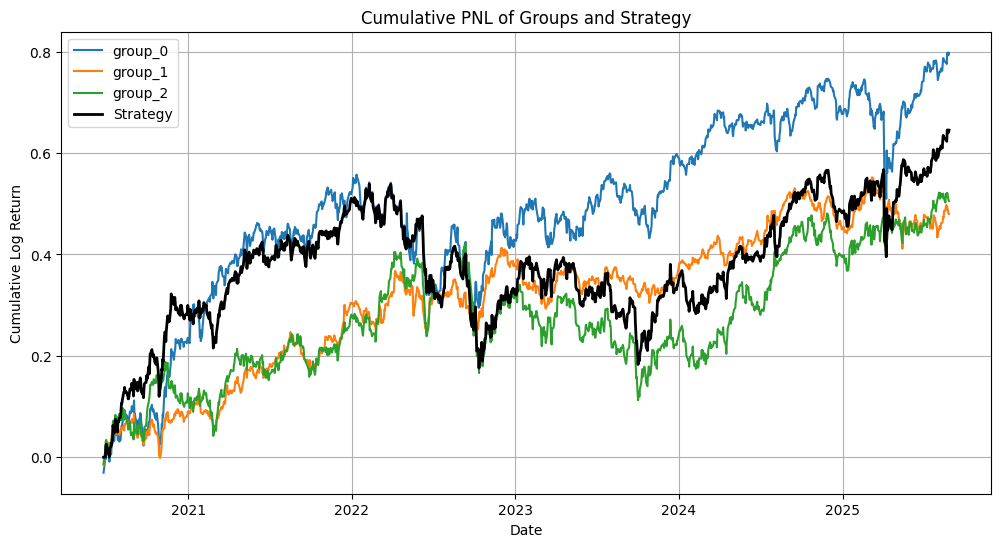

Strategy Sharpe: 0.65
Strategy Max Drawdown: -0.98


In [ ]:
run()